## Question:
### How many turns will a player expect going third out of four to land on park place then boardwalk?

### Simulation: the random variable im simulating is the amount of turns a player going third will take. one trial has 12 outcomes the amount of spaces a player can move the board is 40 or 0-39 spots the player can move 2-12 spaces the outcomes are 2,3,4,5,6,7,8,9,10,11,12 but the goal is to land on 37 an 39 and we are removing chance and community chest.  

## Analysis:

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import random
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid")

In [3]:
num_trials = 5000  # Number of simulated games to run
park_place = 37
boardwalk = 39
board_size = 40

In [5]:
def simulate_monopoly_sequence():
  current_position = 0
  turns = 0
  state = "LOOKING_FOR_PARK_PLACE"  # States: LOOKING_FOR_PARK_PLACE -> LOOKING_FOR_BOARDWALK
  # can't seperate this code or it doesn't work
  while True:
    turns += 1

    # Roll two 6-sided dice (values 2 to 12)
    die1 = random.randint(1, 6)
    die2 = random.randint(1, 6)
    roll = die1 + die2

    # Move player forward around the circular board (0 to 39)
    current_position = (current_position + roll) % board_size

    # Check state machine logic for sequential landing
    if state == "LOOKING_FOR_PARK_PLACE":
      if current_position == park_place:
        state = "LOOKING_FOR_BOARDWALK"

    elif state == "LOOKING_FOR_BOARDWALK":
      if current_position == boardwalk:
        # Successfully landed on Park Place first, then Boardwalk!
        break

  return turns

In [6]:
results = [simulate_monopoly_sequence() for _ in range(num_trials)]

# Load results into a Pandas DataFrame
df = pd.DataFrame(results, columns=["Turns"])

In [7]:
mean_turns = df["Turns"].mean()
std_turns = df["Turns"].std()

print(f"--- SIMULATION RESULTS ({num_trials} trials) ---")
print(f"Mean turns: {mean_turns:.2f}")
print(f"Standard Deviation: {std_turns:.2f}")

--- SIMULATION RESULTS (5000 trials) ---
Mean turns: 78.50
Standard Deviation: 52.38


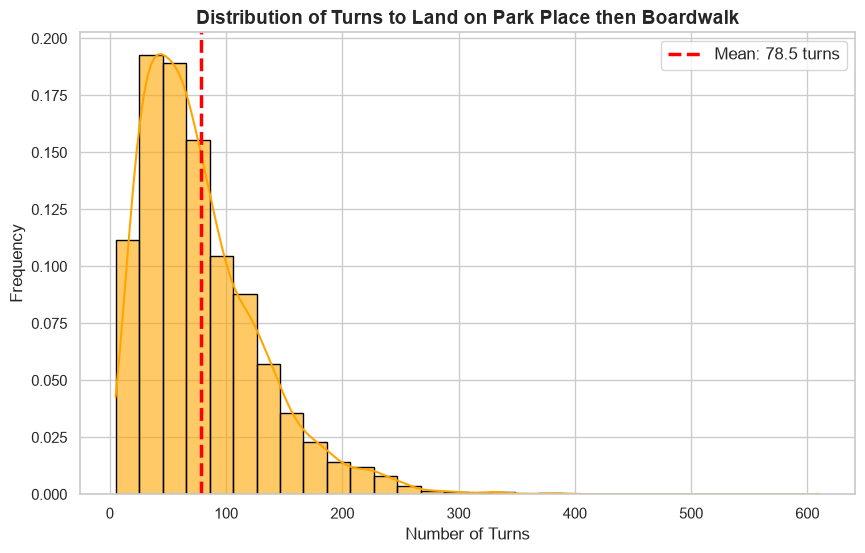

In [15]:
plt.figure(figsize=(10, 6))

# Use seaborn histplot with a KDE (Kernel Density Estimate) curve overlaid
# Use stat="probability" or stat="percent" inside sns.histplot
sns.histplot(
    data=df,
    x="Turns",
    bins=30,
    kde=True,
    stat="probability",  # <-- This changes the y-axis to show probability (0.0 to 1.0)
    color="orange",
    edgecolor="black",
    alpha=0.6,
)

# Add a vertical dashed line for the Mean
plt.axvline(
    mean_turns,
    color="red",
    linestyle="dashed",
    linewidth=2.5,
    label=f"Mean: {mean_turns:.1f} turns",
)

plt.title(
    "Distribution of Turns to Land on Park Place then Boardwalk",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Number of Turns", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend(fontsize=12)

plt.show()

In [11]:
print(df['Turns'].max())

611


## Conclusion

###     In conclusion to answer how many turns in monopoly would a player going third in a group of three  would expect to take which is 78.5 turns thats our mean out of our 5000 simulations as you can see in the code above. so what basically happened over 5000 simulations ran a game over monopoly testing the third player turns out the max turns a player going third is 611 turns in one game to land on park place then boardwalk but as you can see taking our mean from all the data the turns a player going third will land on park place then boardwalk. Even the histogram above proves this point even though you can't see the data as it goes way low since its right skewed which means most of the data that repeat the amount of turns are in the left side of the graph and will have our mean and median and as you can see our mean in our histogram is 78.5 which is correct because it be close to the center of our histogram as now the histogram proves that the amount of turns could expect in monopoly a player going third is 78.5 turns.